# BIOT 6900 · Module 7 · Assignment Starter (Neo4j)

### *Build a knowledge graph for YOUR Part I disease*

This is the starter for the graded assignment. The database plumbing, the Cypher
queries, and the graph algorithms are **already written and working** — your job
is to supply the **data for your own disease** (the cells marked **`# TODO`**) and
then **interpret** what the graph tells you.

It ships with a tiny placeholder example so it runs top to bottom as a skeleton.
Replace the example with your disease, section by section, re-running as you go.

**Before you start:** create a free Neo4j AuraDB instance and have your
`targets_ad.csv` from Module 2 ready. See the Module 7 lab guide for setup.
Run with **Kernel → Restart & Run All**.


## 0 · Install and connect

Run this, then paste your Neo4j connection details into the next cell. On AuraDB
Free the **username is your instance ID**, not `neo4j`.

In [1]:
# If the kernel restarts after installing, run the cells again from the top.
%pip install neo4j networkx matplotlib pandas requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
from neo4j import GraphDatabase

# Credentials live in a git-ignored file (the Aura "Download credentials" .txt, renamed),
# so the password is never in a committed cell.
CRED_FILE = "neo4j_credentials.txt"
creds = dict(line.strip().split("=", 1) for line in open(CRED_FILE) if "=" in line and not line.startswith("#"))
NEO4J_URI  = creds["NEO4J_URI"]
NEO4J_USER = creds["NEO4J_USERNAME"]      # on AuraDB Free this is the instance ID, not "neo4j"
NEO4J_PASSWORD = creds["NEO4J_PASSWORD"]

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity(); print("Connected to Neo4j.")
except Exception as e:
    print("Not connected yet — check URI/username/password. Details:", e)

Connected to Neo4j.


## 1 · Your data  (★ this is the part you edit)

Replace every value marked **`# TODO`** with your own disease. Read your genes
from `targets_ad.csv`, then fill in the phenotypes, pathways, drugs, variants, and
**at least one related disease that shares a phenotype** (that is what powers the
repurposing query in §4).

In [3]:
import pandas as pd
import networkx as nx
import os

# ===========================================================================
# YOUR DISEASE  —  replace every value marked TODO with your own Part I disease.
# The example values let the notebook run as a skeleton; swap them for yours.
# ===========================================================================
DISEASE = "Type 2 diabetes"          # my Part I disease (Modules 2-4)

# --- Genes: read your targets_ad.csv from Module 2, or edit the example list ---
def load_my_genes(path="data/targets_t2d.csv"):
    if os.path.exists(path):
        df = pd.read_csv(path)
        df = df.astype(object).where(df.notna(), None)     # missing evidence -> None, not NaN
        print(f"loaded {len(df)} genes from {path}")
        # TODO: make sure your columns are named:
        #       gene, ensembl, gwas_p, rna_lfc, prot_lfc, druggability
        return [(r.get("gene"), r.get("ensembl", ""), r.get("gwas_p"),
                 r.get("rna_lfc"), r.get("prot_lfc"), r.get("druggability"))
                for _, r in df.iterrows()]
    print(f"(no file at {path}) — using the EXAMPLE genes; replace them with yours")
    return [
        # symbol,   ensembl,            gwas_p, rna_lfc, prot_lfc, druggability
        ("GENE1",   "ENSG00000000001", 1e-20, 0.9, 0.8, 0.40),    # TODO
        ("GENE2",   "ENSG00000000002", 1e-12, 0.5, 0.4, 0.60),    # TODO
        ("DRUGTGT1","ENSG00000000003", None,  0.1, 0.1, 0.90),    # TODO: a drug-target gene
    ]
GENES = load_my_genes()

# --- The other layers: edit ALL of these for your disease ---
# Sources: Open Targets Platform (GWAS credible sets, HPO phenotypes, Reactome pathways,
# ChEMBL drug mechanisms), queried October 2026. My Module 2/3 evidence is in the CSV.
PHENOTYPES = ["Insulin resistance", "Increased waist to hip ratio",    # HPO terms listed for T2D in Open Targets
              "Hyperglycemia", "Obesity", "Hypertriglyceridemia"]      # HPO terms from the clinical definition
GENE_IN_PATHWAY = {                                                     # Reactome, via Open Targets
    "Regulation of insulin secretion": ["KCNJ11", "ABCC8"],
    "Glucagon-like Peptide-1 (GLP1) regulates insulin secretion": ["GLP1R"],
    "Synthesis, secretion, and inactivation of Glucagon-like Peptide-1 (GLP-1)": ["DPP4"],
    "G alpha (s) signalling events": ["CRH", "GLP1R"],
    "G alpha (i) signalling events": ["NPY"],
    "Signaling by Insulin receptor": ["INSR"],
    "Cellular hexose transport": ["SLC5A2"],
    "Transcriptional regulation of white adipocyte differentiation": ["LPL", "PPARG"],
    "Chylomicron remodeling": ["LPL"],
    "Other interleukin signaling": ["CSF1", "IFNLR1"],
    "Interleukin-17 signaling": ["IL17RB"],
    "TNFR2 non-canonical NF-kB pathway": ["TNFRSF11A"],
    "Neutrophil degranulation": ["CTSZ"],
    "Signaling by ROBO receptors": ["ROBO1", "SLIT2"],
    "RAC1 GTPase cycle": ["BAIAP2"],
    "Integrin signaling": ["APBB1IP"],
    "O-linked glycosylation of mucins": ["MUC13"],
}
PATHWAYS = list(GENE_IN_PATHWAY)
DRUGS = [                                                               # approved, ChEMBL mechanism via Open Targets
    ("Sitagliptin", "DPP4", "approved"), ("Empagliflozin", "SLC5A2", "approved"),
    ("Dapagliflozin", "SLC5A2", "approved"), ("Glimepiride", "ABCC8", "approved"),
    ("Glimepiride", "KCNJ11", "approved"), ("Semaglutide", "GLP1R", "approved"),
    ("Liraglutide", "GLP1R", "approved"), ("Insulin glargine", "INSR", "approved"),
    ("Pioglitazone", "PPARG", "approved"),
]
# Variants: the lead GWAS variant of each gene's best T2D credible set (Open Targets).
# (My Module 5 gene, CYP2C19, is a pharmacogene unrelated to T2D, so its variants are not used here.)
_lead = pd.read_csv("data/targets_t2d.csv").dropna(subset=["lead_variant"])
VARIANTS = list(_lead.drop_duplicates("lead_variant")[["lead_variant", "gene"]].itertuples(index=False, name=None))

# A related disease that SHARES a phenotype — this is what powers the repurposing query.
RELATED = {
    "name":   "Non-alcoholic fatty liver disease",                # MASLD; Open Targets EFO_1001248
    "shares": ["Insulin resistance", "Obesity", "Hypertriglyceridemia"],
    "genes":  [("PNPLA3", "ENSG00000100344", 5.2e-128, None, None, None),     # GWAS, Open Targets
               ("TM6SF2", "ENSG00000213996", 4.1e-113, None, None, None),     # GWAS, Open Targets
               ("THRB",   "ENSG00000151090", None,     None, None, 1.0)],     # drug target, no GWAS
    "drugs":  [("Resmetirom", "THRB", "approved")],                           # THR-beta agonist, approved for MASH
}

# OPTIONAL patient layer — leave [] to skip. (id, age, genotype, prs_percentile, status)
PATIENTS = []   # TODO (optional): e.g. ("P01", 72, "e3/e4", 0.88, "case")

# ---------------------------------------------------------------------------
# Build node/edge collections from the lists above (you shouldn't need to edit).
# ---------------------------------------------------------------------------
NODES, EDGES = {}, []
def add_node(n, k, **p): NODES[n] = dict(kind=k, **p)
def add_edge(s, r, d, **p): EDGES.append(dict(src=s, rel=r, dst=d, **p))

add_node(DISEASE, "disease")
for sym, ens, gp, rna, prot, dg in GENES:
    add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg)
    add_edge(sym, "ASSOCIATED_WITH", DISEASE, pvalue=gp, source=("GWAS" if gp else "pharmacology"))
for ph in PHENOTYPES:
    add_node(ph, "phenotype"); add_edge(DISEASE, "HAS_PHENOTYPE", ph)
for pw in PATHWAYS:
    add_node(pw, "pathway")
for pw, gl in GENE_IN_PATHWAY.items():
    for g in gl:
        if g in NODES: add_edge(g, "PARTICIPATES_IN", pw)
for name, tgt, status in DRUGS:
    add_node(name, "drug", status=status); add_edge(name, "TARGETS", tgt)
for v, g in VARIANTS:
    add_node(v, "variant"); add_edge(v, "OCCURS_IN", g)
# related disease
_r = RELATED
add_node(_r["name"], "disease")
for ph in _r["shares"]:
    if ph not in NODES: add_node(ph, "phenotype")
    add_edge(_r["name"], "HAS_PHENOTYPE", ph)
for sym, ens, gp, rna, prot, dg in _r["genes"]:
    add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg)
    add_edge(sym, "ASSOCIATED_WITH", _r["name"], pvalue=gp, source="GWAS")
for name, tgt, status in _r["drugs"]:
    add_node(name, "drug", status=status); add_edge(name, "TARGETS", tgt)
for pid, age, geno, prs, status in PATIENTS:
    add_node(pid, "patient", age=age, apoe_genotype=geno, prs_percentile=prs, status=status)

# Evidence on every edge: a source and a confidence level.
import math
OT_HPO = {"Insulin resistance", "Increased waist to hip ratio"}
for e in EDGES:
    if e["rel"] == "ASSOCIATED_WITH":
        p = e.get("pvalue")
        e["source"] = "Open Targets GWAS credible set" if p else "Open Targets clinical precedence (drug target)"
        e["confidence"] = ("high" if p and p < 5e-8 else "suggestive" if p else "low (pharmacology, no GWAS)")
        e["neg_log10_p"] = round(-math.log10(p), 1) if p else None
    elif e["rel"] == "HAS_PHENOTYPE":
        listed = e["src"] == DISEASE and e["dst"] in OT_HPO
        e["source"] = "HPO via Open Targets" if listed else "HPO term, curated from the clinical definition"
        e["confidence"] = "high" if listed else "medium"
    elif e["rel"] == "PARTICIPATES_IN":
        e["source"], e["confidence"] = "Reactome via Open Targets", "high (curated)"
    elif e["rel"] == "TARGETS":
        e["source"], e["confidence"] = "ChEMBL mechanism of action via Open Targets", "high (approved drug)"
    elif e["rel"] == "OCCURS_IN":
        e["source"], e["confidence"] = "Open Targets GWAS lead variant", "medium (lead variant, not proven causal)"

# Identifier harmonization: one node per gene symbol, one Ensembl ID per gene.
gene_ids = {n: d["ensembl"] for n, d in NODES.items() if d["kind"] == "gene"}
assert len(set(gene_ids.values())) == len(gene_ids), "two gene nodes share an Ensembl ID"
print(f"{len(gene_ids)} gene nodes, {len(set(gene_ids.values()))} distinct Ensembl IDs")
print("nodes:", len(NODES), " edges:", len(EDGES))
print("disease:", DISEASE)


loaded 22 genes from data/targets_t2d.csv
25 gene nodes, 25 distinct Ensembl IDs
nodes: 77  edges: 84
disease: Type 2 diabetes


## 2 · Load into Neo4j

Provided — no edits needed. Creates a uniqueness constraint, then loads your
nodes and relationships with batched `UNWIND` + `MERGE`.

In [4]:
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")

KIND_LABEL = {"gene":"Gene","disease":"Disease","phenotype":"Phenotype",
              "pathway":"Pathway","drug":"Drug","variant":"Variant","patient":"Patient"}

for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"})
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: v for k, v in e.items() if k not in ("src","dst","rel")}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props""", rows=rows)

print("node counts:", run_query("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC"))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])

node counts: [{'label': 'Entity', 'n': 77}]
relationships: 84


## 3 · A quick look

Provided. Open your instance in the Aura console and run
`MATCH (n) RETURN n LIMIT 100` to see the graph you just loaded, or use §7 to draw it.

## 4 · Query it — the opening question (Cypher)

Provided. These answer the opening question for whatever `DISEASE` you set in §1.

> **TODO (report):** after running, note which drugs come back, and for the
> repurposing query, which related disease and shared symptom produced each hit.

In [5]:
# 2 hops: drugs acting on genes associated with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(dis:Disease)
    WHERE dis.name = $disease
    RETURN d.name AS drug, g.name AS gene, d.status AS status
    ORDER BY drug
""", disease=DISEASE)

[{'drug': 'Dapagliflozin', 'gene': 'SLC5A2', 'status': 'approved'},
 {'drug': 'Empagliflozin', 'gene': 'SLC5A2', 'status': 'approved'},
 {'drug': 'Glimepiride', 'gene': 'KCNJ11', 'status': 'approved'},
 {'drug': 'Glimepiride', 'gene': 'ABCC8', 'status': 'approved'},
 {'drug': 'Insulin glargine', 'gene': 'INSR', 'status': 'approved'},
 {'drug': 'Liraglutide', 'gene': 'GLP1R', 'status': 'approved'},
 {'drug': 'Pioglitazone', 'gene': 'PPARG', 'status': 'approved'},
 {'drug': 'Semaglutide', 'gene': 'GLP1R', 'status': 'approved'},
 {'drug': 'Sitagliptin', 'gene': 'DPP4', 'status': 'approved'}]

In [6]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate
""", disease=DISEASE)

[{'repurposing_candidate': 'Resmetirom',
  'gene': 'THRB',
  'via_disease': 'Non-alcoholic fatty liver disease',
  'shared_symptoms': ['Insulin resistance',
   'Obesity',
   'Hypertriglyceridemia']}]

## 5 · Biomarker prioritization (centrality)

Provided. PageRank fused with your gene evidence.

> **TODO (report):** which genes rank highest? Does that match the biology you
> expect for your disease? Flag any non-obvious hit.

In [7]:
# PageRank in NetworkX, fused with your gene evidence (runs on any Neo4j tier).
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
rows = [{"gene": n, "pagerank": round(pr[n], 4), "gwas_p": d.get("gwas_p"),
         "druggability": d.get("druggability")}
        for n, d in G.nodes(data=True) if d["kind"] == "gene"]
biomarkers = pd.DataFrame(rows).sort_values("pagerank", ascending=False)
print("Candidate biomarkers for", DISEASE, "(PageRank + evidence):")
print(biomarkers.to_string(index=False))


Candidate biomarkers for Type 2 diabetes (PageRank + evidence):
     gene  pagerank        gwas_p  druggability
    GLP1R    0.0217  4.700000e-22         1.000
    PPARG    0.0165  3.000000e-78         1.000
     INSR    0.0165  3.000000e-14         1.000
   SLC5A2    0.0165           NaN         1.000
   KCNJ11    0.0139 1.000000e-107         1.000
     CSF1    0.0113  1.000000e-14         0.694
     CTSZ    0.0113  5.000000e-14         0.596
     DPP4    0.0113           NaN         1.000
  APBB1IP    0.0113  8.000000e-13         0.093
    MUC13    0.0113  5.700000e-09         0.201
   IL17RB    0.0113  8.200000e-09         0.726
   PCDH17    0.0113  7.000000e-17         0.048
TNFRSF11A    0.0113  2.000000e-21         0.322
    SLIT2    0.0113  6.000000e-09         0.240
    PAMR1    0.0113  6.800000e-06         0.406
   IFNLR1    0.0113  2.000000e-13         0.110
   BAIAP2    0.0113  2.600000e-09         0.010
    ROBO1    0.0113  1.000000e-08         0.316
      NPY    0.0113  1.0

In [8]:
# Extra: fuse PageRank with the gene evidence into ONE ranked score.
# Each component is turned into a percentile rank across genes (missing evidence -> 0), then averaged.
import numpy as np
ev = pd.DataFrame([{"gene": n, "pagerank": pr[n],
                    "gwas": -np.log10(d["gwas_p"]) if d.get("gwas_p") else 0.0,
                    "druggability": d.get("druggability") or 0.0,
                    "protein": abs(d.get("prot_lfc") or 0.0)}
                   for n, d in G.nodes(data=True) if d["kind"] == "gene"])
parts = ["pagerank", "gwas", "druggability", "protein"]
ev["fused_score"] = ev[parts].rank(pct=True).mean(axis=1).round(3)
ev["rank"] = ev.fused_score.rank(ascending=False, method="first").astype(int)
fused = ev.sort_values("rank")
print("Fused candidate-biomarker ranking (mean percentile of PageRank, GWAS -log10 p, druggability, |protein effect|):")
print(fused.round({"pagerank": 4, "gwas": 1, "druggability": 2, "protein": 2}).to_string(index=False))
fused.to_csv("biomarker_ranking.csv", index=False)


Fused candidate-biomarker ranking (mean percentile of PageRank, GWAS -log10 p, druggability, |protein effect|):
     gene  pagerank  gwas  druggability  protein  fused_score  rank
    GLP1R    0.0217  21.3          1.00     0.00        0.715     1
    PPARG    0.0165  77.5          1.00     0.00        0.705     2
   KCNJ11    0.0139 107.0          1.00     0.00        0.700     3
TNFRSF11A    0.0113  20.7          0.32     0.91        0.675     4
     INSR    0.0165  13.5          1.00     0.00        0.645     5
      LPL    0.0113  20.7          0.30     0.84        0.635     6
     CSF1    0.0113  14.0          0.69     0.66        0.625     7
     CTSZ    0.0113  13.3          0.60     0.66        0.595     8
   IL17RB    0.0113   8.1          0.73     0.58        0.530     9
      NPY    0.0113  11.0          0.45     0.56        0.530    10
    PAMR1    0.0113   5.2          0.41     0.84        0.530    11
    ABCC8    0.0087 107.0          1.00     0.00        0.520    12
   S

## 6 · Communities

Provided. Modularity clustering groups densely connected nodes.

> **TODO (report):** pick ONE community and read it as a subtype or mechanism
> hypothesis.

In [9]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(G.to_undirected())
print(f"{len(comms)} communities:")
for i, c in enumerate(comms):
    print(f"  {i}: {sorted(c)}")


17 communities:
  0: ['CRH', 'G alpha (s) signalling events', 'GLP1R', 'Glucagon-like Peptide-1 (GLP1) regulates insulin secretion', 'Liraglutide', 'Semaglutide', 'rs11337932', 'rs9366994']
  1: ['Hypertriglyceridemia', 'Insulin resistance', 'Non-alcoholic fatty liver disease', 'Obesity', 'PNPLA3', 'Resmetirom', 'THRB', 'TM6SF2']
  2: ['Chylomicron remodeling', 'LPL', 'PPARG', 'Pioglitazone', 'Transcriptional regulation of white adipocyte differentiation', 'rs17036160', 'rs17091891']
  3: ['Hyperglycemia', 'Increased waist to hip ratio', 'PAMR1', 'PCDH17', 'Type 2 diabetes', 'rs11148426', 'rs7942287']
  4: ['CSF1', 'IFNLR1', 'Other interleukin signaling', 'rs12721515', 'rs78312791']
  5: ['ROBO1', 'SLIT2', 'Signaling by ROBO receptors', 'rs10511124', 'rs2046438']
  6: ['ABCC8', 'Glimepiride', 'KCNJ11', 'Regulation of insulin secretion', 'rs5215']
  7: ['Cellular hexose transport', 'Dapagliflozin', 'Empagliflozin', 'SLC5A2']
  8: ['INSR', 'Insulin glargine', 'Signaling by Insulin recept

## 7 · Visualize and export

Provided. Draws your graph coloured by kind and exports your node/edge table.
Both the figure and the CSV are graded artifacts — commit them.

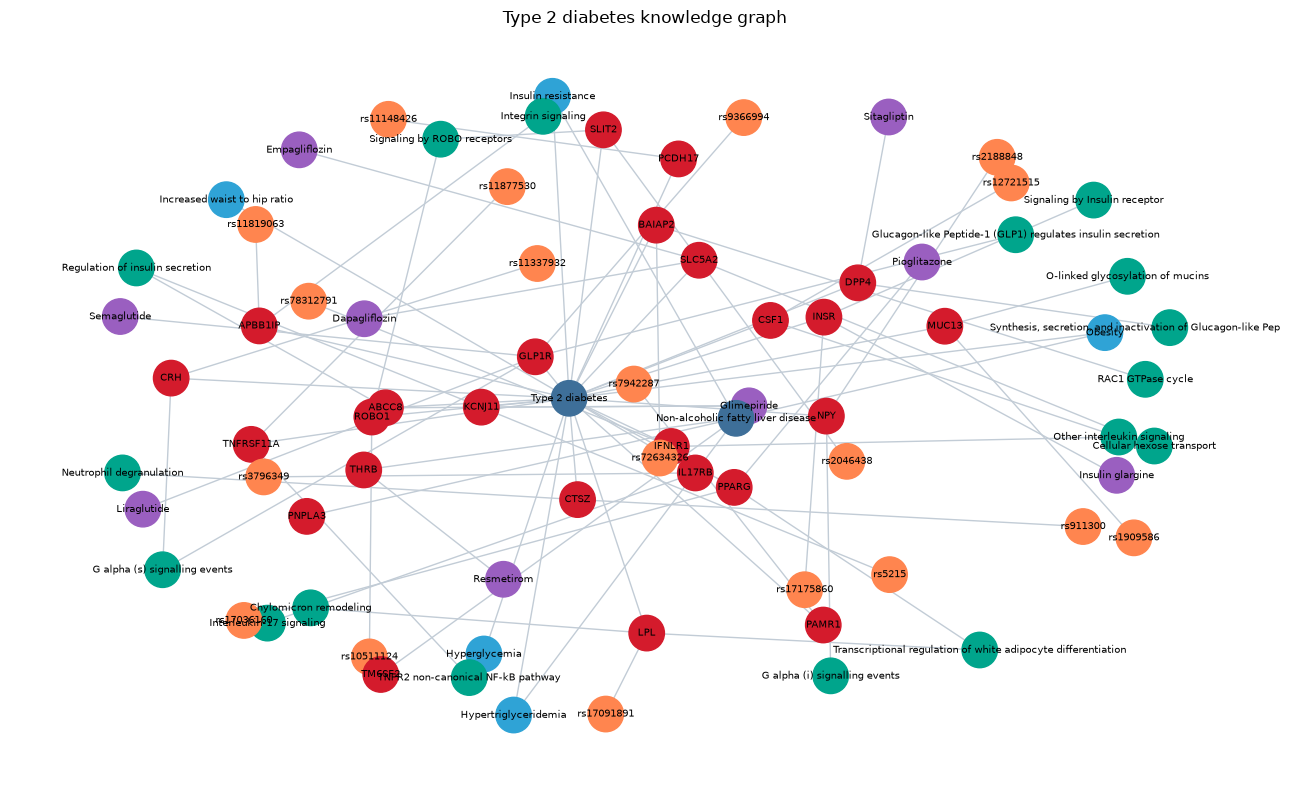

saved my_knowledge_graph.png, nodes.csv, edges.csv


In [10]:
import matplotlib.pyplot as plt

KIND_COLOR = {"gene":"#D41B2C","disease":"#3E6F99","phenotype":"#2FA3D6",
              "pathway":"#00A58C","drug":"#9A5FC0","variant":"#FF854F","patient":"#8A94A3"}
H = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
pos = nx.spring_layout(H, seed=7, k=0.7)
plt.figure(figsize=(13, 8))
nx.draw_networkx_edges(H, pos, edge_color="#C2CCD6", width=1.0, arrows=False)
nx.draw_networkx_nodes(H, pos, node_size=650,
                       node_color=[KIND_COLOR[H.nodes[n]["kind"]] for n in H.nodes()])
nx.draw_networkx_labels(H, pos, font_size=7)
plt.axis("off"); plt.title(f"{DISEASE} knowledge graph"); plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=150, bbox_inches="tight")   # <- commit this
plt.show()

# export node and edge tables (commit the CSVs)
pd.DataFrame([dict(name=n, **d) for n, d in NODES.items()]).to_csv("nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("edges.csv", index=False)
print("saved my_knowledge_graph.png, nodes.csv, edges.csv")

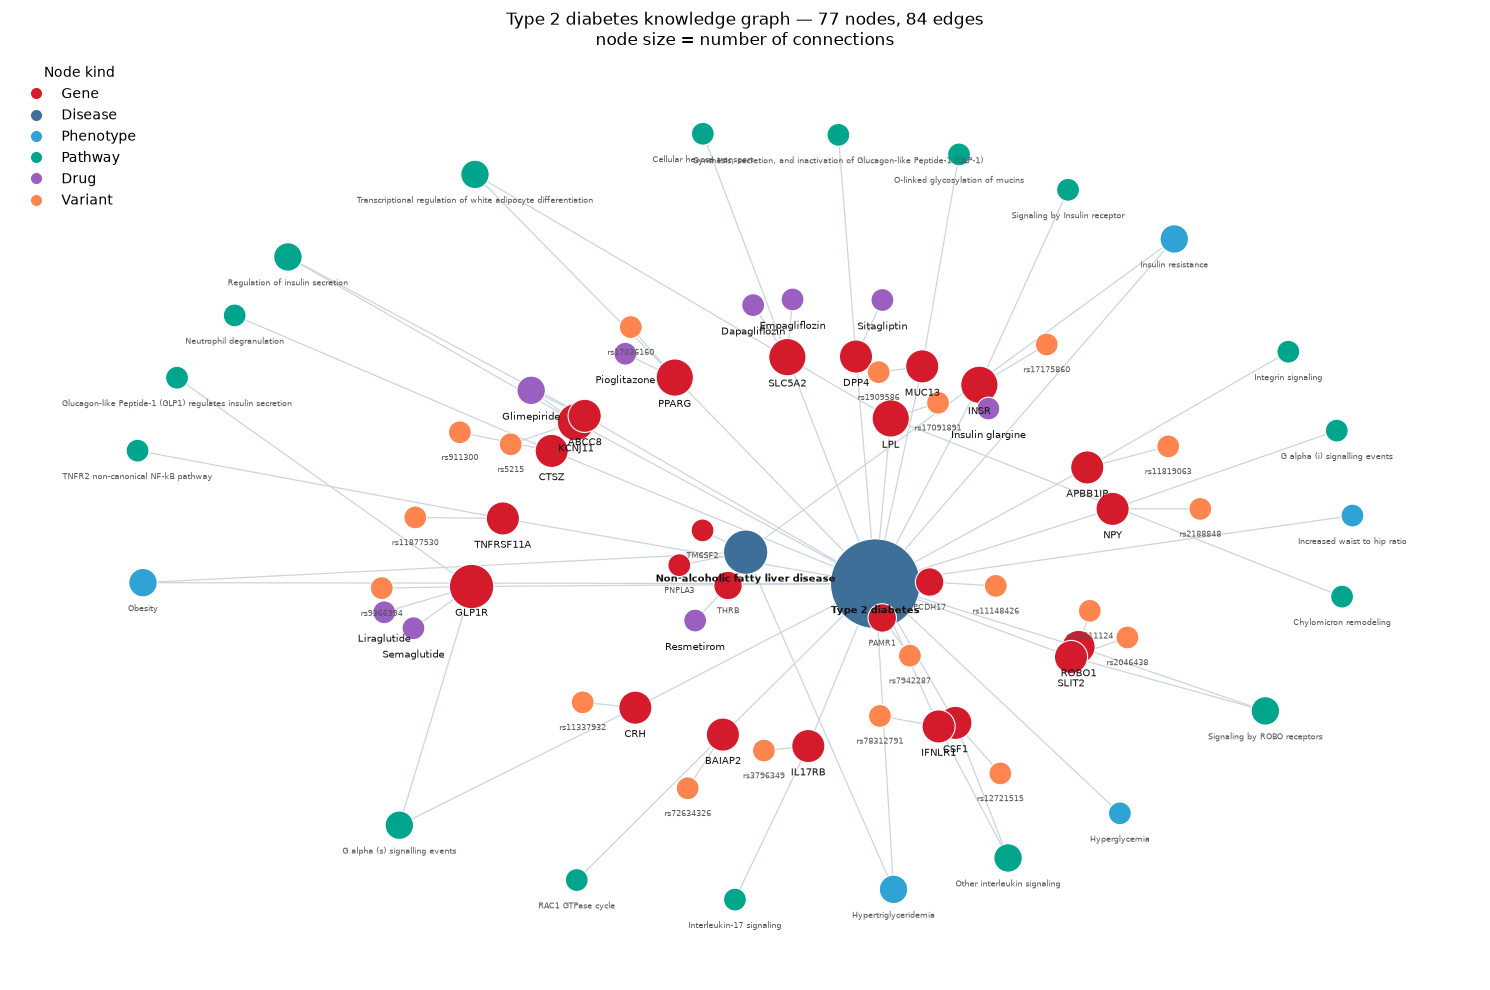

saved my_knowledge_graph.png (legended version)


In [11]:
# Extra: a clearer version of the same figure for the report — adds a legend for node kind,
# sizes nodes by degree, and separates the labels. Same graph, same data as the cell above.
from matplotlib.lines import Line2D

H2 = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
deg = dict(H2.degree())
pos2 = nx.spring_layout(H2, seed=11, k=1.35, iterations=400)

fig, ax = plt.subplots(figsize=(15, 10))
nx.draw_networkx_edges(H2, pos2, edge_color="#CBD5DF", width=0.9, arrows=False, ax=ax)
nx.draw_networkx_nodes(H2, pos2, ax=ax, node_size=[120 + 150 * deg[n] for n in H2.nodes()],
                       node_color=[KIND_COLOR[H2.nodes[n]["kind"]] for n in H2.nodes()],
                       edgecolors="white", linewidths=0.8)
for n, (x, y) in pos2.items():
    big = deg[n] >= 3 or H2.nodes[n]["kind"] in ("disease", "drug")
    ax.text(x, y - 0.052, n, fontsize=7.5 if big else 6, ha="center", va="top",
            color="#111" if big else "#555",
            fontweight="bold" if H2.nodes[n]["kind"] == "disease" else "normal")
ax.legend(handles=[Line2D([], [], marker="o", ls="", markersize=9, markerfacecolor=c,
                          markeredgecolor="white", label=k.capitalize())
                   for k, c in KIND_COLOR.items() if k != "patient"],
          loc="upper left", frameon=False, fontsize=10, title="Node kind", title_fontsize=10)
ax.set_title(f"{DISEASE} knowledge graph — {H2.number_of_nodes()} nodes, {H2.number_of_edges()} edges\n"
             "node size = number of connections", fontsize=12)
ax.axis("off"); plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=170, bbox_inches="tight")   # the graded figure
plt.show()
print("saved my_knowledge_graph.png (legended version)")


## 8 · Your report (the 40%)

Write a **3–4 page report** answering these four, in your own words:

1. **Schema and evidence** — why these node and edge types, and what evidence you put on the edges.
2. **Top targets** — which genes rank highest by centrality (§5), and does that match the biology you expect? Any non-obvious hit?
3. **A hypothesis from a path** — one repurposing or shared-mechanism hypothesis a path in your graph suggests (§4), and what would test it.
4. **Limitations** — an edge is evidence, not truth. Which of your edges are weak, and how would the answer change with better data? Note where you used (or would use) AI to harmonize data or write queries, and how you checked it.

#### Submit
- This notebook (**Kernel → Restart & Run All** first; credentials in a git-ignored file, not committed).
- `my_knowledge_graph.png`, `nodes.csv`, `edges.csv`.
- Your 3–4 page report (PDF) and a short README (name + your disease).
- Push to your biot6900 repo and post the link on Canvas.

#### Reset (to start over)
```cypher
MATCH (n) DETACH DELETE n      // wipes the database — run deliberately
```
